# LCL + EoH linkage: the synthetic heat-pump dataset (`LCL_EoH_join_v6`)

No GB dataset records both a household's whole-meter load and whether it has a heat pump. The
labelled set is therefore built by **superposition**: the measured load of a real Electrification
of Heat (EoH) heat pump is added, half-hour by half-hour, to the measured load of a real Low Carbon
London (LCL) household that heats with gas.

The dataset is built by `create_hp_dataset_v6.py`, which section 0 runs if its outputs are
missing. Its rules are set out below. This notebook reads the build's outputs and produces two tables and three figures.

**Two sets, built by the same method:**

| Set | Host households | Heat pumps | Used for |
|---|---|---|---|
| Training | LCL arm N (standard tariff), survey-confirmed gas homes | E.ON and Warmworks | PU training and the held-out test |
| Transfer | LCL arm D (dynamic time-of-use tariff), survey-confirmed gas homes | OVO | The transfer test only |

**The join rules:**
- **Hosts.** A heat pump goes only on a home whose stated space *and* water heating are both gas,
  and only on a host of the same dwelling type: house to house, flat to flat. Electrically heated
  and mixed-fuel homes stay in the data as households without a heat pump. They are the
  confounder the classifier must reject.
- **Window.** Calendar 2013 for every household. It is the only complete LCL year, and the year
  arm D was on the dynamic tariff.
- **Day matching.** For each host date, add the paired heat pump's day from the same month ± 1 and
  the same weekday/weekend class whose site temperature is closest to the London daily mean.
  Each recorded heat-pump day is used **at most twice** per household. If every candidate is
  already at that limit, the closest is used anyway, and this is counted. A date with no
  candidate is dropped from that heat-pump household, and this is counted too.
- **Temperature.** One London series (Open-Meteo, GMT) is given to every household, with or without
  a heat pump. The site temperature is used only to choose the day, never stored. A leak audit
  checks that temperature alone cannot predict the label.
- **Clock.** LCL and EoH are both GMT, and both are labelled by the start of each half-hour.

## 0. Build the dataset

This cell runs `create_hp_dataset_v6.py`, which writes `LCL_EoH_join_v6/`. It builds only when the outputs are
missing, so rerunning the notebook does not rebuild the heat-pump dataset. Set `REBUILD = True` to build it again.

In [1]:
import subprocess
import sys
from pathlib import Path

REBUILD = False
SCRIPT = Path.cwd() / "create_hp_dataset_v6.py"
BUILD_DIR = Path.cwd() / "LCL_EoH_join_v6"
OUTPUTS = [BUILD_DIR / "join_manifest.json",
          BUILD_DIR / "transfer_armD_ovo/join_manifest.json"]

if REBUILD or not all(p.exists() for p in OUTPUTS):
    # Run the build in its own process and show its log here as it runs.
    proc = subprocess.Popen([sys.executable, "-u", str(SCRIPT)], cwd=SCRIPT.parent,
                            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        # Paths relative to the repository root, so the log shows no local folders.
        print(line.replace(str(SCRIPT.parent) + "/", "").replace(str(SCRIPT.parent), "."), end="")
    if proc.wait() != 0:
        raise RuntimeError(f"{SCRIPT.name} failed (exit code {proc.returncode})")
else:
    print(f"{BUILD_DIR.name} already built; set REBUILD = True to build it again")

LCL_EoH_join_v6: survey hosts, 2013, capped temperature matching

STEP 1: London weather, 2013, GMT (shared by every household)
  fetched 8,760 hourly values from Open-Meteo
  365 days | mean 9.96 °C | no daily cache to check against

STEP 2: LCL households qualifying in 2013
arm  households  gas
  D        1021  651
  N        4005 1296
  87,372,270 half-hourly rows in 2013

STEP 3: EoH usable days and properties (cleaned cache, period start)
contractor  stratum
E.ON        Flat        16
            House      280
OVO         Flat        12
            House      114
Warmworks   Flat        15
            House      288
  725 properties | 489,170 usable property-days | 0.6% of days need interpolation

STEP 4: Pairing (1x, dwelling-matched)
  training: 599 positives on arm N | House 568, Flat 31
  transfer: 126 positives on arm D | House 114, Flat 12

STEP 5 [training]: capped nearest-temperature day selection
  216,827 matched household-days (5s)

STEP 6 [training]: half-hourly, dail

## 1. Setup

In [2]:
from pathlib import Path
import json
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore", category=FutureWarning)

NB_DIR = Path.cwd()
CACHE_DIR = NB_DIR / "cache"
FIG_DIR = NB_DIR / "figures"
TAB_DIR = NB_DIR / "tables"
for d in (FIG_DIR, TAB_DIR):
    d.mkdir(exist_ok=True)

V6 = NB_DIR / "LCL_EoH_join_v6"   # created by create_hp_dataset_v6.py
SETS = {"Training": V6, "Transfer": V6 / "transfer_armD_ovo"}
for p in SETS.values():
    assert (p / "join_manifest.json").exists(), f"build output missing: {p}"

HEAT_GROUPS = ["Gas", "Mixed", "Electric only", "Other fuel", "Unknown", "No survey response"]
HP_LABELS = {"ASHP": "Air source", "HT_ASHP": "High-temp. air source",
             "GSHP": "Ground source", "Hybrid": "Hybrid (HP + boiler)"}

WINTER_MONTHS, SUMMER_MONTHS = (12, 1, 2), (6, 7, 8)   # calendar 2013, as in 01_lcl_analysis
MIN_SEASON_DAYS = 15     # complete days a household needs in a season for Table HP_J_T2
COMPLETE_DAY_SLOTS = 46

# Heat-pump households reach about 1.03 kWh per half-hour, so this is the scale for Figure HP_J3.
# Figures LCL6 and EoH4 (01_lcl_analysis, 02_eoh_analysis) use the same 0-1.05 scale.
HEATMAP_VMAX_HP = 1.05

In [3]:
# --- Figure style, shared by every notebook ---
CAT = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "violet": "#4a3aa7",
       "red": "#e34948", "grey": "#52514e"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
WINTER_COLOR, SUMMER_COLOR, ALLYEAR_COLOR = CAT["blue"], CAT["orange"], INK_SECONDARY
MONTH_LABELS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

SEQ_BLUE_CMAP = LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "font.family": "serif", "font.serif": ["DejaVu Serif", "Georgia", "Times New Roman"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.facecolor": SURFACE,
})

COL_WIDTH = 3.5
COLUMN_RC = {"font.size": 8, "axes.titlesize": 8.5, "axes.labelsize": 8,
             "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7}


def hhmm_axis(ax, step_hours=3):
    # Label a 48-slot time-of-day x-axis; slot i spans [i, i+1) (period start).
    ticks = list(range(0, 49, step_hours * 2))
    ax.set_xticks(ticks)
    ax.set_xticklabels(["24:00" if t == 48 else f"{t // 2:02d}:{'00' if t % 2 == 0 else '30'}"
                        for t in ticks])


def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight")
    print(f"saved -> figures/{name}.png")


def savetable(df, name):
    df.to_csv(TAB_DIR / f"{name}.csv")
    print(f"saved -> tables/{name}.csv")
    return df

In [4]:
manifest = {k: json.load(open(p / "join_manifest.json")) for k, p in SETS.items()}
meta = {k: pd.read_parquet(p / "hp_metadata.parquet") for k, p in SETS.items()}
for k, m in manifest.items():
    gates = m["gates"]
    flat = {g: v for g, v in gates.items() if not isinstance(v, dict)}
    flat.update({f"6_{g}": v for g, v in gates.get("6_holdout_integrity", {}).items()})
    print(f"{k}: {m['households']:,} households, {m['positives']} positives "
          f"({m['prevalence']:.1%}); gates " + ", ".join(
              f"{g} {'PASS' if v else 'FAIL'}" for g, v in flat.items()))

Training: 4,005 households, 599 positives (15.0%); gates 1_leak_audit PASS, 2_positives_on_gas PASS, 3_appliances PASS, 4_confounders PASS, 5_matching PASS, 6_no_ovo_in_training PASS, 6_transfer_positives_all_ovo PASS, 6_no_household_in_both PASS, 6_no_arm_d_in_training PASS
Transfer: 1,021 households, 126 positives (12.3%); gates 1_leak_audit PASS, 2_positives_on_gas PASS, 5_matching PASS, 6_no_ovo_in_training PASS, 6_transfer_positives_all_ovo PASS, 6_no_household_in_both PASS, 6_no_arm_d_in_training PASS


## 2. Table HP_J_T1 - The two sets

Indented rows are subsets of the row above. Heating type comes from the LCL appliance survey.
"No survey response" households have no stated heating type and are kept as households without a
heat pump. Matching statistics are over every heat-pump household-day.

In [5]:
def pct(x):
    return f"{x:.1f}%"


rows = {}
for k in SETS:
    m, d = manifest[k], meta[k]
    pos, neg = d[d.label == 1], d[d.label == 0]
    col = {}
    col["Households"] = f"{m['households']:,}"
    col["  with a heat pump (positives)"] = f"{m['positives']:,}"
    col["    prevalence"] = pct(100 * m["prevalence"])
    col["    hosted by a house"] = f"{m['positives_by_stratum'].get('House', 0):,}"
    col["    hosted by a flat"] = f"{m['positives_by_stratum'].get('Flat', 0):,}"
    for t, lab in HP_LABELS.items():
        col[f"    {lab}"] = f"{m['positives_by_hp_type'].get(t, 0):,}"
    col["  without a heat pump (negatives)"] = f"{len(neg):,}"
    for g in HEAT_GROUPS:
        col[f"    {g}"] = f"{(neg.heat_group == g).sum():,}"
    gap = m["matching_gap_c"]
    col["Heat-pump household-days"] = f"{int(d.loc[d.label == 1, 'n_days'].sum()):,}"
    col["  temperature gap, median (°C)"] = f"{gap['median']:.3f}"
    col["  temperature gap, 90th percentile (°C)"] = f"{gap['p90']:.2f}"
    col["  days with a gap over 1 °C"] = pct(gap["pct_over_1c"])
    col["  days using a capped heat-pump day (fallback)"] = (
        f"{m['reuse']['cap_fallback_dates']:,} ({m['reuse']['households_with_cap_fallback']} households)")
    col["  dates dropped, no candidate day"] = (
        f"{m['dropped_dates']['total']:,} ({pct(m['dropped_dates']['pct_of_positive_dates'])})")
    col["  heat-pump days interpolated (44–47 slots)"] = f"{m['eoh_days_interpolated']:,}"
    col["Leak audit: temperature-only ROC-AUC"] = f"{m['leak_audit_auc']:.3f}"
    rows[f"{k} (arm {m['arm']})"] = col

t_j1 = pd.DataFrame(rows)
t_j1.index.name = "HP_J_T1  LCL_EoH_join_v6"
savetable(t_j1, "HP_J_T1_v6_sets")
t_j1

saved -> tables/HP_J_T1_v6_sets.csv


,Training (arm N),Transfer (arm D)
HP_J_T1 LCL_EoH_join_v6,,
Households,"4,005","1,021"
with a heat pump (positives),599,126
prevalence,15.0%,12.3%
hosted by a house,568,114
hosted by a flat,31,12
Air source,202,103
High-temp. air source,223,8
Ground source,26,11
Hybrid (HP + boiler),148,4


## 3. Figure HP_J1 - One constructed household, a cold week and a mild week

A single training household, chosen without looking at its load: among air-source heat pumps
hosted by a house, the one whose added winter energy is the median. Each panel stacks the host's
own load and the added heat-pump load, half-hour by half-hour, with the London temperature that
every household carries. The cold week is the 2013 week with the lowest mean temperature; the
mild week is the one whose mean is closest to 12 °C.

In [6]:
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
tr = meta["Training"]
cand = tr[(tr.label == 1) & (tr.hp_type == "ASHP") & (tr.eoh_dwelling_type == "House")]
con.register("cand", cand[["household_id", "lcl_id"]])
added = con.execute(f"""
    WITH host AS (
        SELECT household_id, date,
               (2 * hour(period_start) + (minute(period_start) >= 30)::INT + 1)::INT AS hh_index,
               kwh FROM '{CACHE_DIR}/n_ext.parquet'
        WHERE year(date) = 2013 AND household_id IN (SELECT lcl_id FROM cand))
    SELECT c.household_id, h.date, h.hh_index, h.kwh AS host_kwh,
           p.kwh - h.kwh AS hp_kwh, p.temperature
    FROM '{SETS["Training"]}/hp_dataset_hh30.parquet' p
    JOIN cand c ON c.household_id = p.household_id
    JOIN host h ON h.household_id = c.lcl_id AND h.date = p.date AND h.hh_index = p.hh_index
""").df()
added["date"] = pd.to_datetime(added.date)
winter = (added[added.date.dt.month.isin([1, 2, 12])]
          .groupby(["household_id", "date"]).hp_kwh.sum()
          .groupby("household_id").mean().sort_values())
chosen = winter.index[len(winter) // 2]
one = added[added.household_id == chosen].sort_values(["date", "hh_index"])
print(f"{len(winter)} air-source house heat pumps; chosen {chosen} "
      f"(mean winter heat-pump load {winter[chosen]:.1f} kWh/day)")

weather = pd.read_parquet(V6 / "london_weather_2013.parquet")
weather["date"] = weather.time.dt.normalize()
dmean = weather.groupby("date").temp.mean()
weeks = dmean.rolling(7).mean().shift(-6).dropna()
have = one.groupby("date").size()
full = set(have[have >= 46].index)
ok = [d for d in weeks.index if all(d + pd.Timedelta(days=i) in full for i in range(7))]
cold_start = weeks.loc[ok].idxmin()
mild_start = (weeks.loc[ok] - 12).abs().idxmin()

188 air-source house heat pumps; chosen HP_N0646_EOH2549 (mean winter heat-pump load 19.0 kWh/day)


saved -> figures/HP_J1_example_household_weeks.png


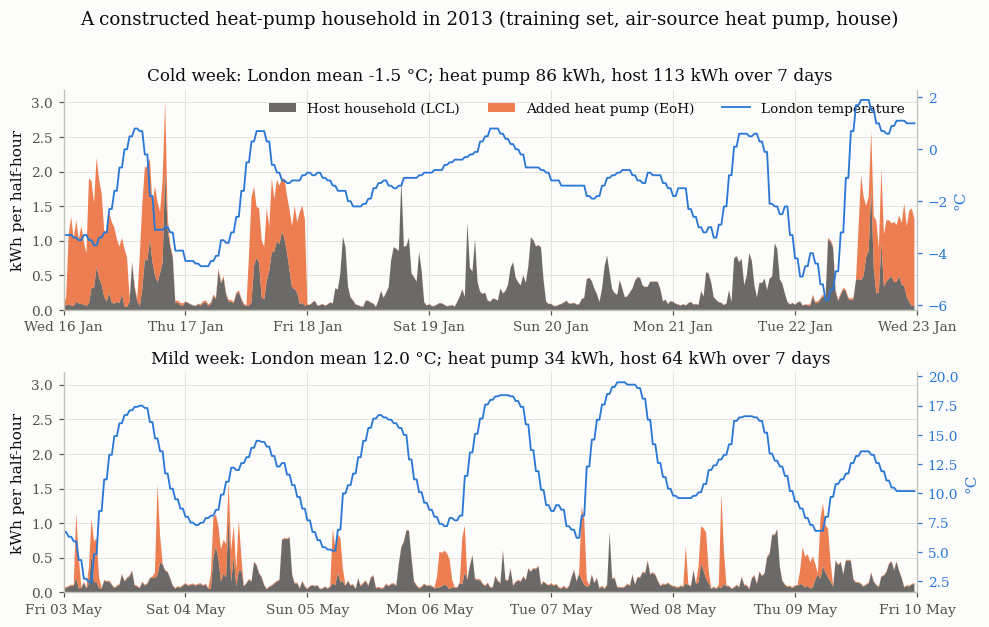

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharey=True)
for ax, start, label in [(axes[0], cold_start, "Cold week"), (axes[1], mild_start, "Mild week")]:
    wk = one[(one.date >= start) & (one.date < start + pd.Timedelta(days=7))].copy()
    x = (wk.date - start).dt.days * 48 + wk.hh_index - 1
    ax.stackplot(x, wk.host_kwh, wk.hp_kwh, colors=[CAT["grey"], CAT["orange"]], alpha=0.85,
                 labels=["Host household (LCL)", "Added heat pump (EoH)"], linewidth=0)
    ax.set_xlim(0, 7 * 48)
    ax.set_xticks(range(0, 7 * 48 + 1, 48))
    ax.set_xticklabels([(start + pd.Timedelta(days=i)).strftime("%a %d %b") for i in range(8)])
    ax.set_ylabel("kWh per half-hour")
    tw = ax.twinx()
    tw.plot(x, wk.temperature, color=CAT["blue"], linewidth=1.2, label="London temperature")
    tw.set_ylabel("°C", color=CAT["blue"])
    tw.tick_params(axis="y", colors=CAT["blue"])
    tw.grid(False)
    tw.spines["right"].set_visible(True)
    ax.set_title(f"{label}: London mean {wk.temperature.mean():.1f} °C; heat pump "
                 f"{wk.hp_kwh.sum():.0f} kWh, host {wk.host_kwh.sum():.0f} kWh over 7 days")
    if label == "Cold week":
        h1, l1 = ax.get_legend_handles_labels()
        h2, l2 = tw.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc="upper right", frameon=False, ncol=3)
fig.suptitle("A constructed heat-pump household in 2013 (training set, air-source heat pump, house)",
             y=1.01)
fig.tight_layout()
savefig(fig, "HP_J1_example_household_weeks")
plt.show()

## 4. Table HP_J_T2 - Winter and summer consumption, heat-pump households against the rest

Each household's mean daily kWh over its complete days (at least 46 of 48 half-hours) in winter
(January, February and December 2013) and summer (June to August). A household needs at least
15 complete days in each season. Heat-pump households include the added heat-pump load. The rest
are every household without a heat pump in the same arm, electrically heated homes included.

In [8]:
con = duckdb.connect()
con.execute("SET preserve_insertion_order=false")
season_rows = []
for k, p in SETS.items():
    s = con.execute(f"""
        WITH d AS (
            SELECT household_id, date, min(label) AS label, sum(kwh) AS kwh
            FROM '{p}/hp_dataset_hh30.parquet' GROUP BY 1, 2
            HAVING count(*) >= {COMPLETE_DAY_SLOTS})
        SELECT household_id, min(label) AS label,
               avg(kwh) FILTER (WHERE month(date) IN {WINTER_MONTHS}) AS winter,
               count(*) FILTER (WHERE month(date) IN {WINTER_MONTHS}) AS n_winter,
               avg(kwh) FILTER (WHERE month(date) IN {SUMMER_MONTHS}) AS summer,
               count(*) FILTER (WHERE month(date) IN {SUMMER_MONTHS}) AS n_summer
        FROM d GROUP BY 1""").df()
    s = s[(s.n_winter >= MIN_SEASON_DAYS) & (s.n_summer >= MIN_SEASON_DAYS)]
    s["set"] = k
    season_rows.append(s)
season = pd.concat(season_rows)
season["ratio"] = season.winter / season.summer.where(season.summer > 0.05)

arm = {k: manifest[k]["arm"] for k in SETS}
cols = {}
for k in SETS:
    for lab, name in [(1, "heat pump"), (0, "no heat pump")]:
        g = season[(season.set == k) & (season.label == lab)]
        cols[f"Arm {arm[k]}, {name}"] = {
            "Households": f"{len(g):,}",
            "Winter kWh/day, mean": f"{g.winter.mean():.1f}",
            "Winter kWh/day, median": f"{g.winter.median():.1f}",
            "Summer kWh/day, mean": f"{g.summer.mean():.1f}",
            "Summer kWh/day, median": f"{g.summer.median():.1f}",
            "Winter/summer ratio, median household": f"{g.ratio.median():.2f}",
        }
t_j2 = pd.DataFrame(cols)
t_j2.index.name = "HP_J_T2  Winter and summer consumption, 2013"
savetable(t_j2, "HP_J_T2_seasonal_consumption")
t_j2

saved -> tables/HP_J_T2_seasonal_consumption.csv


,"Arm N, heat pump","Arm N, no heat pump","Arm D, heat pump","Arm D, no heat pump"
"HP_J_T2 Winter and summer consumption, 2013",,,,
Households,599,"3,406",126,895
"Winter kWh/day, mean",29.5,12.2,35.6,11.4
"Winter kWh/day, median",27.8,9.5,33.9,9.0
"Summer kWh/day, mean",10.5,8.1,11.3,7.6
"Summer kWh/day, median",9.5,6.9,10.7,6.6
"Winter/summer ratio, median household",2.80,1.31,3.17,1.31


## 5. Figure HP_J2 - Mean half-hourly load of heat-pump households

Mean kWh per half-hour over every 2013 reading of the heat-pump households in each set: winter
(January, February and December), summer (June to August) and the whole year. The load is the
host's own plus the added heat pump. Both panels share the y-axis.

saved -> figures/HP_J2_load_profiles_hp_households.png


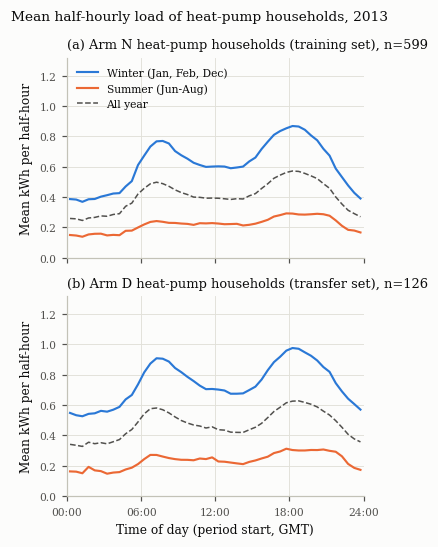

Training: winter peak 0.868 kWh at slot 37, winter/summer daily energy 2.81x
Transfer: winter peak 0.976 kWh at slot 37, winter/summer daily energy 3.16x


In [9]:
prof = {}
for k, p in SETS.items():
    prof[k] = con.execute(f"""
        SELECT hh_index,
               avg(kwh) AS all_year,
               avg(kwh) FILTER (WHERE month(date) IN {WINTER_MONTHS}) AS winter,
               avg(kwh) FILTER (WHERE month(date) IN {SUMMER_MONTHS}) AS summer
        FROM '{p}/hp_dataset_hh30.parquet' WHERE label = 1
        GROUP BY 1 ORDER BY 1""").df()

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.0), sharex=True, sharey=True)
    for ax, k, tag in zip(axes, SETS, "ab"):
        p = prof[k]
        x = p.hh_index - 0.5
        ax.plot(x, p.winter, color=WINTER_COLOR, linewidth=1.4, label="Winter (Jan, Feb, Dec)")
        ax.plot(x, p.summer, color=SUMMER_COLOR, linewidth=1.4, label="Summer (Jun-Aug)")
        ax.plot(x, p.all_year, color=ALLYEAR_COLOR, linewidth=1.0, linestyle="--", label="All year")
        ax.set_title(f"({tag}) Arm {arm[k]} heat-pump households ({k.lower()} set), "
                     f"n={manifest[k]['positives']:,}", loc="left")
        ax.set_ylabel("Mean kWh per half-hour")
    hhmm_axis(axes[1], step_hours=6)
    axes[1].set_xlim(0, 48)
    axes[1].set_xlabel("Time of day (period start, GMT)")
    # Headroom above the morning peak so the legend sits clear of the curves.
    axes[0].set_ylim(0, max(p.winter.max() for p in prof.values()) * 1.35)
    axes[0].legend(frameon=False, loc="upper left")
    fig.suptitle("Mean half-hourly load of heat-pump households, 2013", fontsize=9)
    fig.tight_layout()
    savefig(fig, "HP_J2_load_profiles_hp_households")
    plt.show()

for k, p in prof.items():
    print(f"{k}: winter peak {p.winter.max():.3f} kWh at slot {int(p.loc[p.winter.idxmax(), 'hh_index'])}, "
          f"winter/summer daily energy {p.winter.sum() / p.summer.sum():.2f}x")

## 6. Figure HP_J3 - Heat map of heat-pump households by month and time of day

Each cell is the mean kWh per half-hour across the heat-pump households of that set, for that
month and time of day in 2013. The colour scale runs from 0 to 1.05 kWh and is shared with
Figures LCL6 and EoH4, so the household-only, heat-pump-only and combined loads can be compared
directly. The combined load reaches about 1 kWh per half-hour on winter mornings.

Training: max cell 0.915 kWh
Transfer: max cell 1.039 kWh
saved -> figures/HP_J3_heat_map_hp_households.png


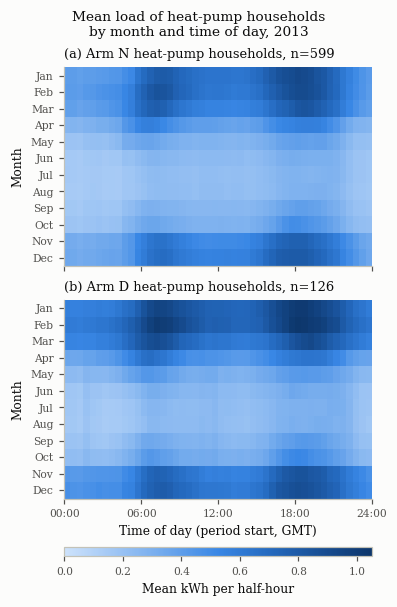

In [10]:
hm = {}
for k, p in SETS.items():
    hm[k] = con.execute(f"""
        SELECT month(date) AS month, hh_index, avg(kwh) AS mean_kwh
        FROM '{p}/hp_dataset_hh30.parquet' WHERE label = 1
        GROUP BY 1, 2""").df()
con.close()

with plt.rc_context(COLUMN_RC):
    fig, axes = plt.subplots(2, 1, figsize=(COL_WIDTH, 5.4), sharex=True, layout="constrained")
    for ax, k, tag in zip(axes, SETS, "ab"):
        mat = (hm[k].pivot_table(index="month", columns="hh_index", values="mean_kwh")
               .reindex(index=range(1, 13), columns=range(1, 49)))
        im = ax.imshow(mat.values, aspect="auto", origin="upper", cmap=SEQ_BLUE_CMAP,
                       vmin=0, vmax=HEATMAP_VMAX_HP, extent=[0, 48, 12, 0])
        ax.set_yticks(np.arange(12) + 0.5)
        ax.set_yticklabels(MONTH_LABELS)
        ax.set_ylabel("Month")
        ax.set_title(f"({tag}) Arm {arm[k]} heat-pump households, n={manifest[k]['positives']:,}",
                     loc="left")
        ax.grid(False)
        print(f"{k}: max cell {np.nanmax(mat.values):.3f} kWh")
    hhmm_axis(axes[1], step_hours=6)
    axes[1].set_xlabel("Time of day (period start, GMT)")
    # One horizontal colour bar under both maps.
    cbar = fig.colorbar(im, ax=axes, orientation="horizontal", fraction=0.05, pad=0.02, aspect=35)
    cbar.set_label("Mean kWh per half-hour")
    fig.suptitle("Mean load of heat-pump households\nby month and time of day, 2013", fontsize=9)
    savefig(fig, "HP_J3_heat_map_hp_households")
    plt.show()

## 7. Notes and limitations

- Each heat-pump household combines a 2013 London home with a heat pump monitored in 2020–23
  elsewhere in GB. Weather and dwelling type are matched, but floor area, insulation and occupancy
  are not.
- Almost all EoH heat pumps are in houses, so dwelling type is linked to the label. Results are
  also reported for houses alone.
- Each recorded heat-pump day is used at most twice per household, and a few dates are dropped
  from heat-pump households where no matching day exists (Table HP_J_T1).
- Summer matching is the weakest, but heat-pump load is small in summer.
- The EoH winters include a lockdown and the energy-price crisis, which shaped how the heat pumps
  were used.
- Prevalence (about 15% in training and 12% in transfer) is set by the number of heat pumps
  available, so precision and F1 have to be restated at a realistic prevalence.